In [3]:
from qdrant_client import models, QdrantClient
from sentence_transformers import SentenceTransformer
from pathlib import Path
from pypdf import PdfReader
from tqdm.auto import tqdm
import pandas as pd
import os
from finrag.extraction import pdf_reader
from concurrent.futures import ProcessPoolExecutor
from itertools import chain

c:\Users\domen\Desktop\Agenti\Progetto\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
os.cpu_count()

20

In [3]:
PDF_DIR = Path("../data/raw/pdfs")

pdf_paths = sorted(PDF_DIR.glob("*.pdf"))
print(f"Numero di file: {len(pdf_paths)}")
with ProcessPoolExecutor(max_workers=15) as executor:
    list_pages_psdfs = list(chain.from_iterable(tqdm(executor.map(pdf_reader, pdf_paths), total=len(pdf_paths), desc="Estrazione PDF")))
df_pdfs=pd.DataFrame(list_pages_psdfs)

print(df_pdfs.shape)

print(df_pdfs.head())

Numero di file: 368


Estrazione PDF: 100%|██████████| 368/368 [05:55<00:00,  1.04it/s]


(53901, 4)
   page_num     doc_name  n_chars  \
0         0  3M_2015_10K     3880   
1         1  3M_2015_10K     1679   
2         2  3M_2015_10K     3862   
3         3  3M_2015_10K     5266   
4         4  3M_2015_10K     5030   

                                                text  
0  Table of Contents\n \n \nlow\n \nUNITED STATES...  
1  Table of Contents\n \n3M COMPANY\nFORM 10-K\nF...  
2  Table of Contents\n \n3M COMPANY\nANNUAL REPOR...  
3  Table of Contents\n \nglobal supplier of preci...  
4  Table of Contents\n \nsurgical settings. Other...  


In [4]:
df_pdfs.to_json("../data/processed/pdfs_pages_data.json",orient="records",lines=True,force_ascii=False)

In [2]:
df_pdfs=pd.read_json("../data/processed/pdfs_pages_data.json",orient="records",lines=True)

In [5]:
df_pdfs.describe()

,page_num,n_chars
count,53901.000000,53901.000000
mean,112.812304,3379.525482
std,102.533622,1632.295808
min,0.000000,0.000000
25%,41.000000,2141.000000
50%,86.000000,3395.000000
75%,149.000000,4557.000000
max,666.000000,16759.000000


<Axes: >

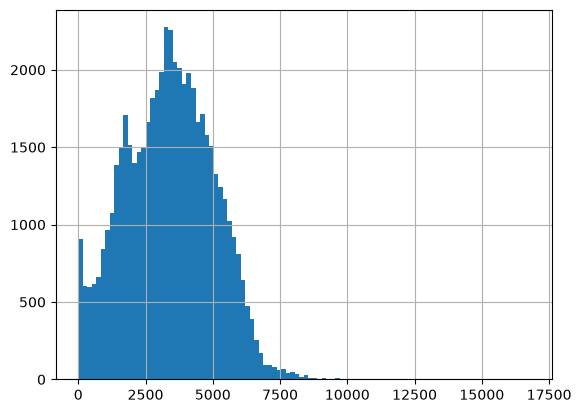

In [6]:
df_pdfs["n_chars"].hist(bins=100)

In [9]:
df_empty=df_pdfs[df_pdfs["n_chars"]==0]


In [10]:
df_pdf_only=df_empty.groupby("doc_name").size()
df_pdf_only.describe()
#le pagine vuote sono distribuite tra i pdf

count    60.000000
mean      1.900000
std       1.791695
min       1.000000
25%       1.000000
50%       1.000000
75%       2.000000
max       9.000000
dtype: float64

In [4]:
from difflib import SequenceMatcher
# 1. Caricamento
df_questions = pd.read_json("../data/processed/financebench_p.json", lines=True)
df_pages = pd.read_json("../data/processed/pdfs_pages_data.json", lines=True) 

df_ev=(
    df_questions[["financebench_id","evidence"]]
    .explode("evidence")
    .reset_index(drop=True)
)

df_ev.head()

,financebench_id,evidence
0,financebench_id_03029,{'evidence_text': 'Table of Contents 3M Compa...
1,financebench_id_04672,{'evidence_text': 'Table of Contents 3M Compa...
2,financebench_id_00499,{'evidence_text': '3M Company and Subsidiaries...
3,financebench_id_00499,{'evidence_text': '3M Company and Subsidiaries...
4,financebench_id_00499,{'evidence_text': '3M Company and Subsidiaries...


In [7]:
# 3. Dal dizionario alle colonne
#se hai un json puoi espanderlo nello colonne del df con json normalize
ev_cols=pd.json_normalize(df_ev["evidence"])
ev_cols.head()

,evidence_text,doc_name,evidence_page_num,evidence_text_full_page
0,Table of Contents \n3M Company and Subsidiarie...,3M_2018_10K,59,Table of Contents \n3M Company and Subsidiarie...
1,Table of Contents \n3M Company and Subsidiarie...,3M_2018_10K,57,Table of Contents \n3M Company and Subsidiarie...
2,3M Company and Subsidiaries\nConsolidated Stat...,3M_2022_10K,47,Table of Contents\n3M Company and Subsidiaries...
3,3M Company and Subsidiaries\nConsolidated Bala...,3M_2022_10K,49,Table of Contents\n3M Company and Subsidiaries...
4,3M Company and Subsidiaries\nConsolidated Stat...,3M_2022_10K,51,Table of Contents\n3M Company and Subsidiaries...


In [14]:
ev_cols=ev_cols.rename(columns={"doc_name":"ev_doc_name"})
#Merge con pagine estratte
df_ev = pd.concat([df_ev[["financebench_id"]], ev_cols], axis=1)

df_check=df_ev.merge(
    df_pages,
    right_on=["page_num","doc_name"],
    left_on=["evidence_page_num","ev_doc_name"],
    how="left"
)

df_check.head()




,financebench_id,evidence_text,ev_doc_name,evidence_page_num,evidence_text_full_page,page_num,doc_name,n_chars,text
0,financebench_id_03029,Table of Contents \n3M Company and Subsidiarie...,3M_2018_10K,59,Table of Contents \n3M Company and Subsidiarie...,59,3M_2018_10K,3049,Table of Contents\n \n3M Company and Subsidiar...
1,financebench_id_04672,Table of Contents \n3M Company and Subsidiarie...,3M_2018_10K,57,Table of Contents \n3M Company and Subsidiarie...,57,3M_2018_10K,2381,Table of Contents\n \n3M Company and Subsidiar...
2,financebench_id_00499,3M Company and Subsidiaries\nConsolidated Stat...,3M_2022_10K,47,Table of Contents\n3M Company and Subsidiaries...,47,3M_2022_10K,1517,T\nable of \nContents\n3M Company and Subsidia...
3,financebench_id_00499,3M Company and Subsidiaries\nConsolidated Bala...,3M_2022_10K,49,Table of Contents\n3M Company and Subsidiaries...,49,3M_2022_10K,2180,T\nable of \nContents\n3M Company and Subsidia...
4,financebench_id_00499,3M Company and Subsidiaries\nConsolidated Stat...,3M_2022_10K,51,Table of Contents\n3M Company and Subsidiaries...,51,3M_2022_10K,2772,T\nable of \nContents\n3M Company and Subsidia...


In [16]:
# 5. Verifiche sul merge
assert len(df_check) == len(df_ev), "Il merge ha cambiato il numero di righe"

missing = df_check[df_check["n_chars"].isna()]
print(f"Evidenze senza pagina corrispondente: {len(missing)}")
print(missing[["financebench_id", "ev_doc_name", "evidence_page_num"]])

print(f"Evidenze su pagine vuote: {(df_check['n_chars'] == 0).sum()}")
print(df_check["n_chars"].describe())




Evidenze senza pagina corrispondente: 0
Empty DataFrame
Columns: [financebench_id, ev_doc_name, evidence_page_num]
Index: []
Evidenze su pagine vuote: 0
count     189.000000
mean     2691.571429
std      1317.843020
min       688.000000
25%      1723.000000
50%      2296.000000
75%      3389.000000
max      7793.000000
Name: n_chars, dtype: float64


In [17]:
# 6. Somiglianza tra la nostra pagina e quella del dataset
def normalize(text):
    if not isinstance(text,str):
        return ""
    return " ".join(text.lower().split())

def similarity(row):
    a=normalize(row["text"])
    b=normalize(row["evidence_text_full_page"])
    if not a or not b:
        return 0
    return SequenceMatcher(None,a,b).ratio()

df_check["similarity"]=df_check.apply(similarity,axis=1)


print(df_check["similarity"].describe())

count    189.000000
mean       0.963097
std        0.104854
min        0.373651
25%        0.987263
50%        0.997000
75%        0.998887
max        1.000000
Name: similarity, dtype: float64


In [21]:
print(df_check.sort_values(by="similarity")[
        ["financebench_id", "ev_doc_name", "evidence_page_num", "n_chars", "similarity"]
    ].head(10))


           financebench_id          ev_doc_name  evidence_page_num  n_chars  \
92   financebench_id_05915   CVSHEALTH_2018_10K                301     2031   
87   financebench_id_10130     CORNING_2020_10K                 71     2461   
70   financebench_id_07661       BLOCK_2020_10K                 89     3547   
68   financebench_id_04660       BLOCK_2016_10K                 67     2247   
93   financebench_id_05915   CVSHEALTH_2018_10K                303     2085   
86   financebench_id_10130     CORNING_2020_10K                 69     1652   
88   financebench_id_02981     CORNING_2021_10K                 64     2469   
60   financebench_id_02608     BESTBUY_2017_10K                 55     1910   
131  financebench_id_03849  MGMRESORTS_2020_10K                 66     4895   
61   financebench_id_04417     BESTBUY_2019_10K                 51     1834   

     similarity  
92     0.373651  
87     0.475813  
70     0.512324  
68     0.517520  
93     0.546425  
86     0.557449  
88  

In [ ]:
from difflib import SequenceMatcher

# 1. Caricamento
df_questions = pd.read_json("../data/processed/financebench_p.json", lines=True)
df_pages = pd.read_json("../data/processed/pdfs_pages_data.json", lines=True)  # <- il tuo file delle pagine

# 2. Una riga per evidenza
df_ev = (
    df_questions[["financebench_id", "evidence"]]
    .explode("evidence")
    .reset_index(drop=True)
)

# 3. Dal dizionario alle colonne
ev_cols = pd.json_normalize(df_ev["evidence"])
# il nome del documento nell'evidenza può chiamarsi in due modi a seconda della versione
if "evidence_doc_name" in ev_cols.columns:
    ev_cols = ev_cols.rename(columns={"evidence_doc_name": "ev_doc_name"})
else:
    ev_cols = ev_cols.rename(columns={"doc_name": "ev_doc_name"})

df_ev = pd.concat([df_ev[["financebench_id"]], ev_cols], axis=1)
print(f"Evidenze totali: {len(df_ev)}")

# 4. Merge con le pagine estratte
df_check = df_ev.merge(
    df_pages,
    left_on=["ev_doc_name", "evidence_page_num"],
    right_on=["doc_name", "page_num"],
    how="left",
)

# 5. Verifiche sul merge
assert len(df_check) == len(df_ev), "Il merge ha cambiato il numero di righe"
missing = df_check[df_check["n_chars"].isna()]
print(f"Evidenze senza pagina corrispondente: {len(missing)}")
print(missing[["financebench_id", "ev_doc_name", "evidence_page_num"]])

print(f"Evidenze su pagine vuote: {(df_check['n_chars'] == 0).sum()}")
print(df_check["n_chars"].describe())

# 6. Somiglianza tra la nostra pagina e quella del dataset
def normalize(text):
    if not isinstance(text, str):
        return ""
    return " ".join(text.lower().split())

def similarity(row):
    a = normalize(row["text"])
    b = normalize(row["evidence_text_full_page"])
    if not a or not b:
        return 0.0
    return SequenceMatcher(None, a, b).ratio()

df_check["similarity"] = df_check.apply(similarity, axis=1)

print(df_check["similarity"].describe())
print(
    df_check.sort_values("similarity")[
        ["financebench_id", "ev_doc_name", "evidence_page_num", "n_chars", "similarity"]
    ].head(15)
)

#il testo delle similarity basse è comunque lo stesso


In [14]:
# Dizionario per trovare velocemente il testo di una pagina: (documento, pagina) -> testo
page_text = {
    (row.doc_name, row.page_num): row.text
    for row in df_pages.itertuples()
}

OFFSETS = [-2, -1, 0, 1, 2]

def best_offset(row):
    target = normalize(row["evidence_text_full_page"])
    scores = {}
    for off in OFFSETS:
        candidate = page_text.get((row["ev_doc_name"], row["evidence_page_num"] + off))
        if candidate is None:
            continue  # pagina fuori dal documento
        scores[off] = SequenceMatcher(None, normalize(candidate), target).ratio()
    best = max(scores, key=scores.get)
    return pd.Series({"best_offset": best, "best_similarity": scores[best]})

low = df_check[df_check["similarity"] < 0.9].copy()
low[["best_offset", "best_similarity"]] = low.apply(best_offset, axis=1)

print(
    low[["financebench_id", "ev_doc_name", "evidence_page_num",
         "similarity", "best_offset", "best_similarity"]]
    .sort_values(["ev_doc_name", "evidence_page_num"])
)

           financebench_id                      ev_doc_name  \
4    financebench_id_00499                      3M_2022_10K   
60   financebench_id_02608                 BESTBUY_2017_10K   
61   financebench_id_04417                 BESTBUY_2019_10K   
68   financebench_id_04660                   BLOCK_2016_10K   
69   financebench_id_03838                   BLOCK_2020_10K   
70   financebench_id_07661                   BLOCK_2020_10K   
86   financebench_id_10130                 CORNING_2020_10K   
87   financebench_id_10130                 CORNING_2020_10K   
88   financebench_id_02981                 CORNING_2021_10K   
92   financebench_id_05915               CVSHEALTH_2018_10K   
93   financebench_id_05915               CVSHEALTH_2018_10K   
117  financebench_id_01487  JOHNSON_JOHNSON_2023Q2_EARNINGS   
129  financebench_id_04171              MGMRESORTS_2018_10K   
130  financebench_id_03849              MGMRESORTS_2020_10K   
131  financebench_id_03849              MGMRESORTS_2020

In [11]:
print(len(df_pages[df_pages["n_chars"]<=100]))

654
